# Generating full songs with vocals

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dorienh/music-ai-explained/blob/main/06-generating-full-songs/notebook.ipynb)

Companion to the article *How AI Generates a Full Song With Vocals*. We count how long a song is in model units, lay lyrics out on a time grid the way DiffRhythm and JAM do, measure whether music returns to itself with a self-similarity matrix, and test whether words survive a codec when the band is loud.

Runs on a CPU. The first run downloads about 1.6 GB (a speech recogniser and MusicGen's codec), plus 2 GB more for the optional MusicGen section.

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q librosa soundfile "transformers>=4.45" faster-whisper

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, librosa, matplotlib.pyplot as plt
from IPython.display import Audio, display

BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "lines.linewidth": 2, "figure.dpi": 110})

def clip(name, sr=None, offset=0.0, duration=None):
    """Load one of librosa's freely licensed example recordings (downloaded on first use)."""
    y, sr = librosa.load(librosa.example(name, hq=True), sr=sr, mono=True, offset=offset, duration=duration)
    return y, sr
import re, torch
from transformers import logging
logging.set_verbosity_error(); torch.set_grad_enabled(False)

## 1. How long is a song, in model units?

In [3]:
SONG = 180
for name, fps, per in [("raw audio, 44.1 kHz stereo", 44100, 2), ("MusicGen tokens (50 Hz, 4 codebooks)", 50, 4),
                       ("YuE stage 1 (50 Hz, vocal + accompaniment)", 50, 2), ("DiffRhythm / JAM latents (21.5 Hz)", 44100 / 2048, 1)]:
    print(f"{name:45s} {fps*SONG:>10,.0f} frames, {fps*SONG*per:>11,.0f} numbers to generate")
print(f"\nattention pairs: 30 s = {1500**2:,}, 3 min = {9000**2:,} ({9000**2 / 1500**2:.0f}x)")

raw audio, 44.1 kHz stereo                     7,938,000 frames,  15,876,000 numbers to generate
MusicGen tokens (50 Hz, 4 codebooks)               9,000 frames,      36,000 numbers to generate
YuE stage 1 (50 Hz, vocal + accompaniment)         9,000 frames,      18,000 numbers to generate
DiffRhythm / JAM latents (21.5 Hz)                 3,876 frames,       3,876 numbers to generate

attention pairs: 30 s = 2,250,000, 3 min = 81,000,000 (36x)


## 2. Lyrics on the time grid

DiffRhythm writes each line's phonemes one per frame from the line's start time. JAM spreads each word's phonemes over the frames the word is sung. `.` = no vocal, `-` = still inside a word. Change the timings and rerun.

In [4]:
FPS = 44100 / 2048
LEX = {"hold": "HH OW L D", "on": "AA N", "to": "T UW", "me": "M IY"}
WORDS = [("hold", 2.00, 2.40), ("on", 2.40, 2.70), ("to", 2.70, 2.90), ("me", 2.90, 3.80)]
N, f = int(4.2 * FPS), lambda t: int(t * FPS)

dr = ["."] * N
ph = [p for w, _, _ in WORDS for p in LEX[w].split()]
dr[f(2.0): f(2.0) + len(ph)] = ph

jam = ["."] * N
for w, s, e in WORDS:
    p, a, b = LEX[w].split(), f(s), f(e)
    jam[a:b] = ["-"] * (b - a)
    for i, x in enumerate(p): jam[a + int(i * (b - a) / len(p))] = x

for name, row in (("sentence-level", dr), ("word-level    ", jam)):
    print(name, " ".join(f"{x:>2}" for x in row[f(1.9):]))
print(f"\n{len(ph)} phonemes packed = {len(ph)/FPS:.2f} s; sung over {3.8-2.0:.2f} s")

sentence-level  .  .  . HH OW  L  D AA  N  T UW  M IY  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .
word-level      .  .  . HH  - OW  -  L  -  D  - AA  -  -  N  -  -  -  T  - UW  -  M  -  -  -  -  -  -  -  - IY  -  -  -  -  -  -  -  -  -  .  .  .  .  .  .  .  .  .

10 phonemes packed = 0.46 s; sung over 1.80 s


## 3. Does it come back? Self-similarity

By hand first: a verse-chorus-verse-chorus song against a piece that keeps moving to new material. The return score is each section's best match at least two sections away, averaged.

In [5]:
def cos_matrix(X):
    X = np.asarray(X, float); X = X / np.linalg.norm(X, axis=1, keepdims=True); return X @ X.T
def return_score(S, min_gap):
    n = len(S); return np.mean([max(S[i, j] for j in range(n) if abs(i - j) >= min_gap) for i in range(n)])

song = cos_matrix([[3, 1], [1, 3], [3, 1.2], [1, 3]])
drift = cos_matrix([[3, 1], [2, 2], [1, 3], [-1, 3]])
print(np.round(song, 2)); print("song return score: ", round(return_score(song, 2), 2))
print(np.round(drift, 2)); print("drift return score:", round(return_score(drift, 2), 2))

[[1.   0.6  1.   0.6 ]
 [0.6  1.   0.65 1.  ]
 [1.   0.65 1.   0.65]
 [0.6  1.   0.65 1.  ]]
song return score:  1.0
[[1.   0.89 0.6  0.  ]
 [0.89 1.   0.89 0.45]
 [0.6  0.89 1.   0.8 ]
 [0.   0.45 0.8  1.  ]]
drift return score: 0.52


Now a real song with vocals: beat-synchronous chroma and MFCC features, stacked over 4 beats, compared with cosine similarity. Stripes parallel to the diagonal are passages that return.

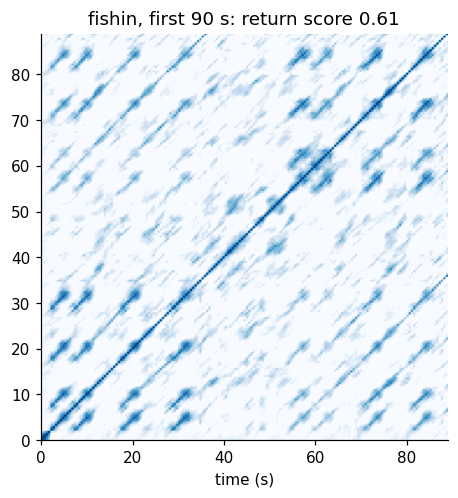

[audio player: run the cell to listen]


In [6]:
import scipy.signal
if not hasattr(scipy.signal, "hann"): scipy.signal.hann = scipy.signal.windows.hann

def ssm(y, sr, min_lag=15.0):
    _, beats = librosa.beat.beat_track(y=y, sr=sr)
    ch = librosa.feature.chroma_cqt(y=y, sr=sr); mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)[1:]
    F = np.vstack([ch / (np.linalg.norm(ch, axis=0) + 1e-9), mf / (np.linalg.norm(mf, axis=0) + 1e-9)])
    F = librosa.util.sync(F, beats, aggregate=np.median); F = F - F.mean(axis=1, keepdims=True)
    F = librosa.feature.stack_memory(F, n_steps=4, mode="edge"); F = F / (np.linalg.norm(F, axis=0) + 1e-9)
    t = np.concatenate([[0.0], librosa.frames_to_time(beats, sr=sr)])[: F.shape[1]]
    S = F.T @ F; far = np.abs(t[:, None] - t[None, :]) >= min_lag
    return S, t, float(np.mean(np.where(far, S, -1).max(axis=1)))

y, sr = clip("fishin", sr=22050, duration=90)
S, t, score = ssm(y, sr)
plt.imshow(S, origin="lower", cmap="Blues", vmin=0, vmax=1, extent=[0, t[-1], 0, t[-1]]); plt.grid(False)
plt.title(f"fishin, first 90 s: return score {score:.2f}"); plt.xlabel("time (s)"); plt.show()
display(Audio(y, rate=sr))

## 4. Do the words survive the codec?

Speech mixed with music at two voice-to-music ratios, passed through MusicGen's codec either as one mix (mixed tokens) or as two separate tracks (split tokens, the idea behind YuE). Word error rate against the transcript of the clean speech. The article's figure averages four voice-music pairs and six ratios (`vocal_masking.py`).

In [7]:
from transformers import EncodecModel
from faster_whisper import WhisperModel
codec = EncodecModel.from_pretrained("facebook/encodec_32khz").eval()
asr = WhisperModel("medium", device="cpu", compute_type="int8")

def through_codec(x):
    enc = codec.encode(torch.tensor(x, dtype=torch.float32)[None, None])
    return codec.decode(enc.audio_codes, enc.audio_scales)[0][0, 0].numpy()[: len(x)]
def transcribe(x, sr=32000):
    segs, _ = asr.transcribe(librosa.resample(x, orig_sr=sr, target_sr=16000).astype(np.float32), language="en", beam_size=5)
    return " ".join(s.text for s in segs)
def wer(ref, hyp):
    r, h = [re.sub(r"[^a-z0-9' ]", " ", s.lower()).split() for s in (ref, hyp)]
    d = np.arange(len(h) + 1)
    for i in range(1, len(r) + 1):
        prev, d[0] = d.copy(), i
        for j in range(1, len(h) + 1): d[j] = min(prev[j] + 1, d[j - 1] + 1, prev[j - 1] + (r[i - 1] != h[j - 1]))
    return d[len(h)] / len(r)

voice, _ = clip("libri1", sr=32000)
music, _ = clip("choice", sr=32000); music = np.resize(music, len(voice))
rms = lambda x: np.sqrt(np.mean(x ** 2))
ref = transcribe(voice); print("reference:", ref)
for var in (0, -8):
    m = music * rms(voice) / rms(music) / 10 ** (var / 20)
    g = np.abs(voice + m).max() / 0.9; v, m = voice / g, m / g
    mixed, split = through_codec(v + m), through_codec(v) + through_codec(m)
    print(f"\nvoice {var:+d} dB vs music: mixed tokens WER {wer(ref, transcribe(mixed)):.0%}, split tokens WER {wer(ref, transcribe(split)):.0%}")
    print("mixed tokens"); display(Audio(mixed, rate=32000)); print("split tokens"); display(Audio(split, rate=32000))

reference:  With her white paint and her scarlet smokestack, the Inverish Heel, one of the two small steamers that during the summer months  plied up and down the lock, and incidentally carried on communication between Inverish Heel and Kryanon.



voice +0 dB vs music: mixed tokens WER 26%, split tokens WER 21%
mixed tokens


[audio player: run the cell to listen]


split tokens


[audio player: run the cell to listen]



voice -8 dB vs music: mixed tokens WER 61%, split tokens WER 45%
mixed tokens


[audio player: run the cell to listen]


split tokens


[audio player: run the cell to listen]


## 5. Chaining 30-second windows (optional, downloads MusicGen, slow on CPU)

Generate 30 s, feed the last 10 s back as a prompt, generate 20 s more. The article's figure chains to 90 s (`generate_long.py`); here we stop at 50 s to keep it quick.

In [8]:
RUN_MUSICGEN = False
if RUN_MUSICGEN:
    from transformers import AutoProcessor, MusicgenForConditionalGeneration
    proc = AutoProcessor.from_pretrained("facebook/musicgen-small")
    mg = MusicgenForConditionalGeneration.from_pretrained("facebook/musicgen-small").eval()
    prompt = "upbeat folk pop song with acoustic guitar, bass, drums and a catchy chorus"
    torch.manual_seed(0)
    out = mg.generate(**proc(text=[prompt], return_tensors="pt"), do_sample=True, guidance_scale=3, max_new_tokens=1500)[0, 0].numpy()
    ctx = out[-10 * 32000:]
    more = mg.generate(**proc(text=[prompt], audio=[ctx], sampling_rate=32000, return_tensors="pt"),
                       do_sample=True, guidance_scale=3, max_new_tokens=1500)[0, 0].numpy()
    long = np.concatenate([out, more[len(ctx):]])
    S, t, score = ssm(librosa.resample(long, orig_sr=32000, target_sr=22050), 22050)
    plt.imshow(S, origin="lower", cmap="Blues", vmin=0, vmax=1, extent=[0, t[-1], 0, t[-1]]); plt.grid(False)
    plt.title(f"MusicGen, two windows: return score {score:.2f}"); plt.show()
    display(Audio(long, rate=32000))

## Where next

- The articles: [Music & AI on Medium](https://medium.com/@dorien-herremans/list/music-ai-3fb88d4826dd)
- For the full picture: [A Tutorial on Generative Models for Music Audio](https://arxiv.org/abs/2610.38252)